# Stage 3: Regression

## Objective

Which factors are most strongly associated with higher spending?

This stage fits an ordered logit model of monthly spending on six predictors, checks its assumptions (VIF, Brant test) and shows the age effect as predicted probabilities. All tables and figures are written to `outputs/stage3/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Output folders for Stage 3 (created if missing)
OUT = Path("../outputs/stage3")
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

d = pd.read_csv("../Dataset/gacha_clean.csv", encoding="utf-8-sig")
print(d.shape)   # expected: (510, 52)

(510, 52)


## 1. Data and model setup

The outcome `SPEND_MONTH4` is monthly spending in four ordered bands. The predictors are three perception scores, satisfaction, tenure and age group.

In [2]:
Y = "SPEND_MONTH4"
X_COLS = ["LUCK", "PITY2", "PRICE", "SAT", "TENURE_code", "AGE_code"]
nhan = {"LUCK": "Perceived luck", "PITY2": "Perceived pity fairness", "PRICE": "Perceived price fairness",
        "SAT": "Satisfaction", "TENURE_code": "Tenure (per group)", "AGE_code": "Age (per group)"}
muc = ["0 VND", "Under 100k", "100k to under 300k", "300k or more"]   # spending levels 0-3
tuoi = ["18-22", "23-27", "28+"]                                     # AGE_code 1-3

y = d[Y].astype(int)
X = d[X_COLS]
bang = pd.DataFrame({"n": y.value_counts().sort_index(), "%": (y.value_counts(normalize=True).sort_index() * 100).round(1)})
bang.index = muc
bang

,n,%
0 VND,218,42.7
Under 100k,110,21.6
100k to under 300k,131,25.7
300k or more,51,10.0


## 2. Ordered logit

Spending is recorded in ordered bands of unequal width, so linear regression is not appropriate. The ordered logit models the cumulative probability of each level $j$:

$$\operatorname{logit} P(Y \le j \mid x) = \ln\frac{P(Y \le j \mid x)}{1 - P(Y \le j \mid x)} = \theta_j - x^\top\beta, \qquad j = 0, 1, 2$$

$$x^\top\beta = \beta_1\,\text{LUCK} + \beta_2\,\text{PITY2} + \beta_3\,\text{PRICE} + \beta_4\,\text{SAT} + \beta_5\,\text{TENURE} + \beta_6\,\text{AGE}$$

$\theta_j$ are thresholds between levels. Each slope is reported as an odds ratio, $OR_k = e^{\beta_k}$, with 95% CI $e^{\beta_k \pm 1.96\,SE_k}$. $OR > 1$ means higher odds of a higher spending level. Fit is measured with $R^2_{McF} = 1 - \ln \hat L_{model} / \ln \hat L_0$.

In [3]:
mo_hinh = OrderedModel(y, X, distr="logit").fit(method="bfgs", disp=0)
k = len(X_COLS)
ci = mo_hinh.conf_int().iloc[:k]
ket_qua = pd.DataFrame({
    "beta": mo_hinh.params[:k], "SE": mo_hinh.bse[:k],
    "OR": np.exp(mo_hinh.params[:k]), "CI_low": np.exp(ci[0]), "CI_high": np.exp(ci[1]),
    "p": mo_hinh.pvalues[:k],
}).round(3)
ket_qua.rename_axis("predictor").to_csv(TAB / "stage3_ordered_logit.csv", encoding="utf-8-sig")
print(f"McFadden R2 = {mo_hinh.prsquared:.3f}, log-likelihood = {mo_hinh.llf:.1f}, AIC = {mo_hinh.aic:.1f}")
ket_qua

McFadden R2 = 0.035, log-likelihood = -626.5, AIC = 1271.1


,beta,SE,OR,CI_low,CI_high,p
LUCK,0.107,0.095,1.113,0.924,1.342,0.260
PITY2,-0.263,0.107,0.769,0.624,0.948,0.014
PRICE,0.255,0.118,1.291,1.024,1.628,0.031
SAT,0.123,0.114,1.130,0.904,1.414,0.283
TENURE_code,0.136,0.098,1.146,0.945,1.389,0.166
AGE_code,1.007,0.169,2.739,1.968,3.811,0.000


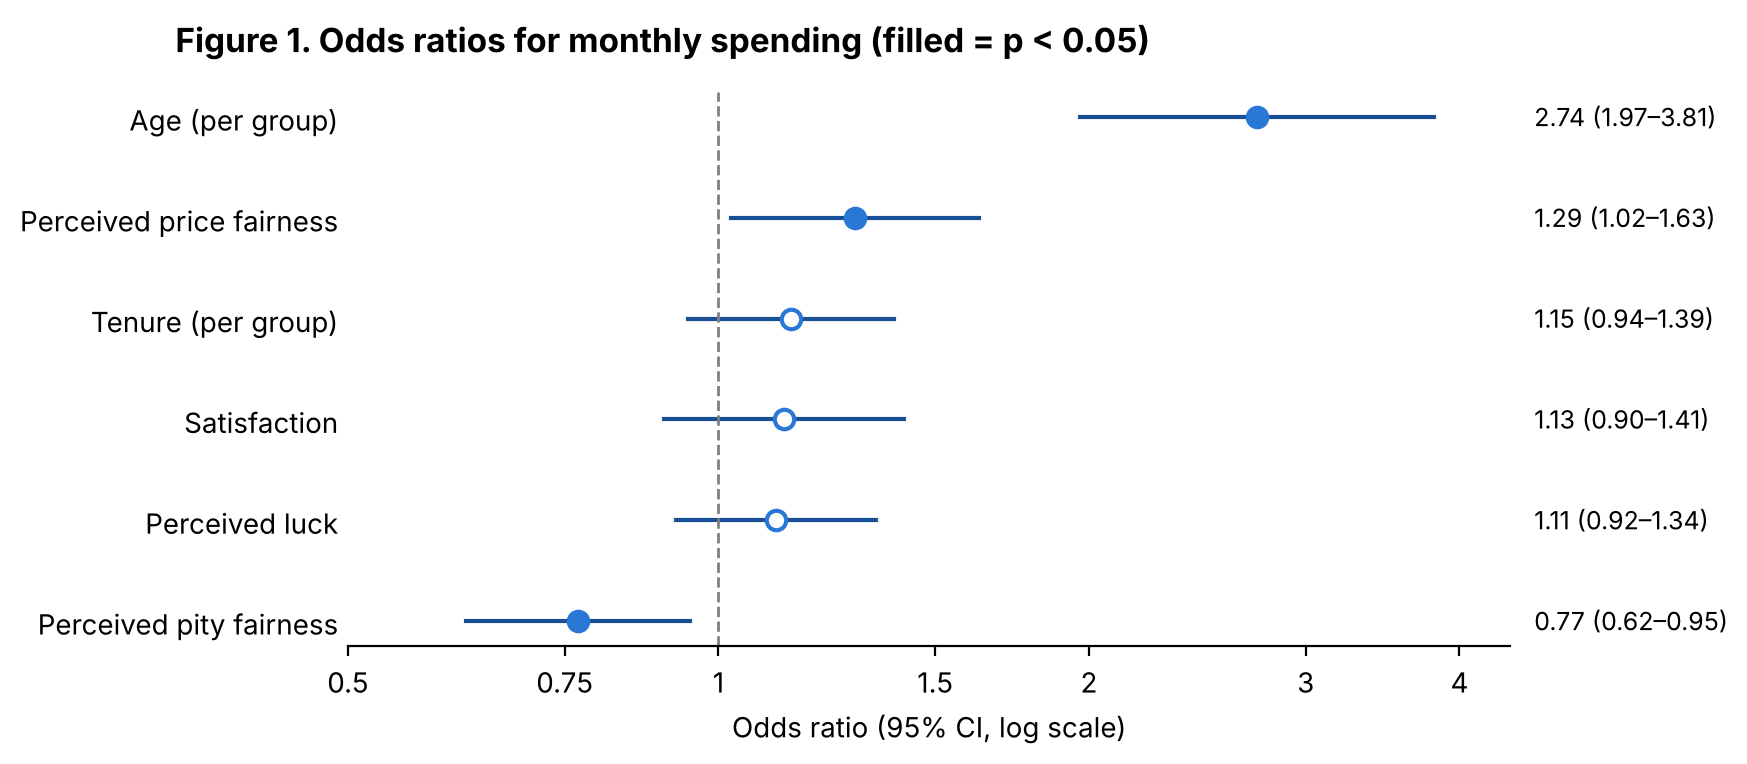

In [4]:
# Forest plot of odds ratios: filled = p < 0.05, open = not significant
thu_tu = ket_qua.sort_values("OR").index
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, name in enumerate(thu_tu):
    r = ket_qua.loc[name]
    ax.plot([r["CI_low"], r["CI_high"]], [i, i], color="#184f95", linewidth=1.5)
    ax.plot(r["OR"], i, "o", ms=7, color="#2a78d6", mfc="#2a78d6" if r["p"] < 0.05 else "white", mew=1.5)
    ax.text(4.6, i, f"{r['OR']:.2f} ({r['CI_low']:.2f}–{r['CI_high']:.2f})", va="center", fontsize=9)
ax.axvline(1, color="grey", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "4"])
ax.minorticks_off(); ax.set_xlim(0.5, 4.4)
ax.set_yticks(range(k)); ax.set_yticklabels([nhan[n] for n in thu_tu])
ax.set_xlabel("Odds ratio (95% CI, log scale)")
ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(axis="y", length=0)
fig.suptitle("Figure 1. Odds ratios for monthly spending (filled = p < 0.05)", x=0.01, ha="left", fontweight="bold")
fig.savefig(FIG / "odds_ratio_forest.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Assumption checks

**Multicollinearity.** $VIF_k = 1 / (1 - R_k^2)$, where $R_k^2$ comes from regressing predictor $k$ on the other five. Values below 5 are acceptable.

In [5]:
Xc = sm.add_constant(X)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X_COLS).round(2)
vif.rename("VIF").rename_axis("predictor").to_csv(TAB / "stage3_vif.csv", encoding="utf-8-sig")
vif.to_frame("VIF")

,VIF
LUCK,1.25
PITY2,1.63
PRICE,1.62
SAT,1.39
TENURE_code,1.02
AGE_code,1.06


**Proportional odds (Brant test).** The model assumes each slope is the same at every threshold. A binary logit is fitted for each split, $\operatorname{logit} P(Y > j \mid x) = \alpha_j + x^\top\beta_j$, and $H_0: \beta_0 = \beta_1 = \beta_2$ is tested with a Wald statistic:

$$W = (D\hat\beta)^\top (D \hat V D^\top)^{-1} (D\hat\beta) \sim \chi^2_{df}$$

$\hat\beta$ stacks the slopes of the three binary logits, $\hat V$ is their joint covariance and $D$ takes the differences between thresholds. $p > 0.05$ means the assumption holds.

In [6]:
def brant_test(y, X):
    Xc = sm.add_constant(X).values
    cuts = sorted(y.unique())[:-1]
    J, p = len(cuts), X.shape[1]
    fits = [sm.Logit((y > c).astype(int), Xc).fit(disp=0) for c in cuts]   # one binary logit per split
    pis = [f.predict(Xc) for f in fits]
    inv = [np.linalg.inv(Xc.T @ (Xc * (pi * (1 - pi))[:, None])) for pi in pis]
    V = np.zeros((J * p, J * p))                                            # joint covariance of all slopes
    for a in range(J):
        for b in range(J):
            if a == b:
                blk = inv[a]
            else:
                lo, hi = min(a, b), max(a, b)
                w = pis[hi] - pis[lo] * pis[hi]
                blk = inv[a] @ (Xc.T @ (Xc * w[:, None])) @ inv[b]
            V[a*p:(a+1)*p, b*p:(b+1)*p] = blk[1:, 1:]
    beta = np.concatenate([f.params[1:] for f in fits])

    def wald(cols):
        D = np.zeros(((J - 1) * len(cols), J * p)); r = 0
        for i in cols:
            for j in range(1, J):
                D[r, i], D[r, j*p + i] = 1, -1; r += 1
        diff = D @ beta
        w = float(diff @ np.linalg.inv(D @ V @ D.T) @ diff)
        return w, D.shape[0], stats.chi2.sf(w, D.shape[0])

    rows = [("Omnibus", *wald(range(p)))] + [(X.columns[i], *wald([i])) for i in range(p)]
    return pd.DataFrame(rows, columns=["term", "chi2", "df", "p"]).round(3)

brant = brant_test(y, X)
brant.to_csv(TAB / "stage3_brant.csv", index=False, encoding="utf-8-sig")
brant

,term,chi2,df,p
0,Omnibus,15.434,12,0.219
1,LUCK,1.400,2,0.497
2,PITY2,2.243,2,0.326
3,PRICE,4.027,2,0.134
4,SAT,3.281,2,0.194
5,TENURE_code,3.695,2,0.158
6,AGE_code,2.863,2,0.239


## 4. Reference model with INT

INT ("I plan to spend") nearly restates the outcome, so it is kept out of the main model and shown only for comparison.

In [7]:
tham_chieu = OrderedModel(y, d[X_COLS + ["INT"]], distr="logit").fit(method="bfgs", disp=0)
fit_tbl = pd.DataFrame({
    "model": ["Main (6 predictors)", "Reference (+ INT)"],
    "n": [len(d), len(d)],
    "mcfadden_r2": [mo_hinh.prsquared, tham_chieu.prsquared],
    "log_likelihood": [mo_hinh.llf, tham_chieu.llf],
    "aic": [mo_hinh.aic, tham_chieu.aic],
}).round(3)
fit_tbl.to_csv(TAB / "stage3_model_fit.csv", index=False, encoding="utf-8-sig")
print(f"OR of INT = {np.exp(tham_chieu.params['INT']):.2f}")
fit_tbl

OR of INT = 3.31


,model,n,mcfadden_r2,log_likelihood,aic
0,Main (6 predictors),510,0.035,-626.549,1271.097
1,Reference (+ INT),510,0.214,-510.405,1040.809


## 5. Age effect

Predicted probability of each spending level by age group, with the other predictors held at their mean, compared with the observed mix.

In [8]:
luoi = pd.DataFrame([X.mean()] * 3).reset_index(drop=True)
luoi["AGE_code"] = [1, 2, 3]
du_doan = pd.DataFrame(np.asarray(mo_hinh.predict(luoi[X_COLS])), index=tuoi, columns=muc)
du_doan.rename_axis("age_group").round(4).to_csv(TAB / "stage3_predicted_by_age.csv", encoding="utf-8-sig")

n_tuoi = d["AGE_code"].value_counts().sort_index().values
quan_sat = pd.crosstab(d["AGE_code"], y, normalize="index")
quan_sat.index = [f"{a} (n = {n})" for a, n in zip(tuoi, n_tuoi)]
quan_sat.columns = muc
(du_doan * 100).round(1)

,0 VND,Under 100k,100k to under 300k,300k or more
18-22,47.7,22.2,22.9,7.1
23-27,25.0,20.9,36.7,17.3
28+,10.8,12.8,39.8,36.5


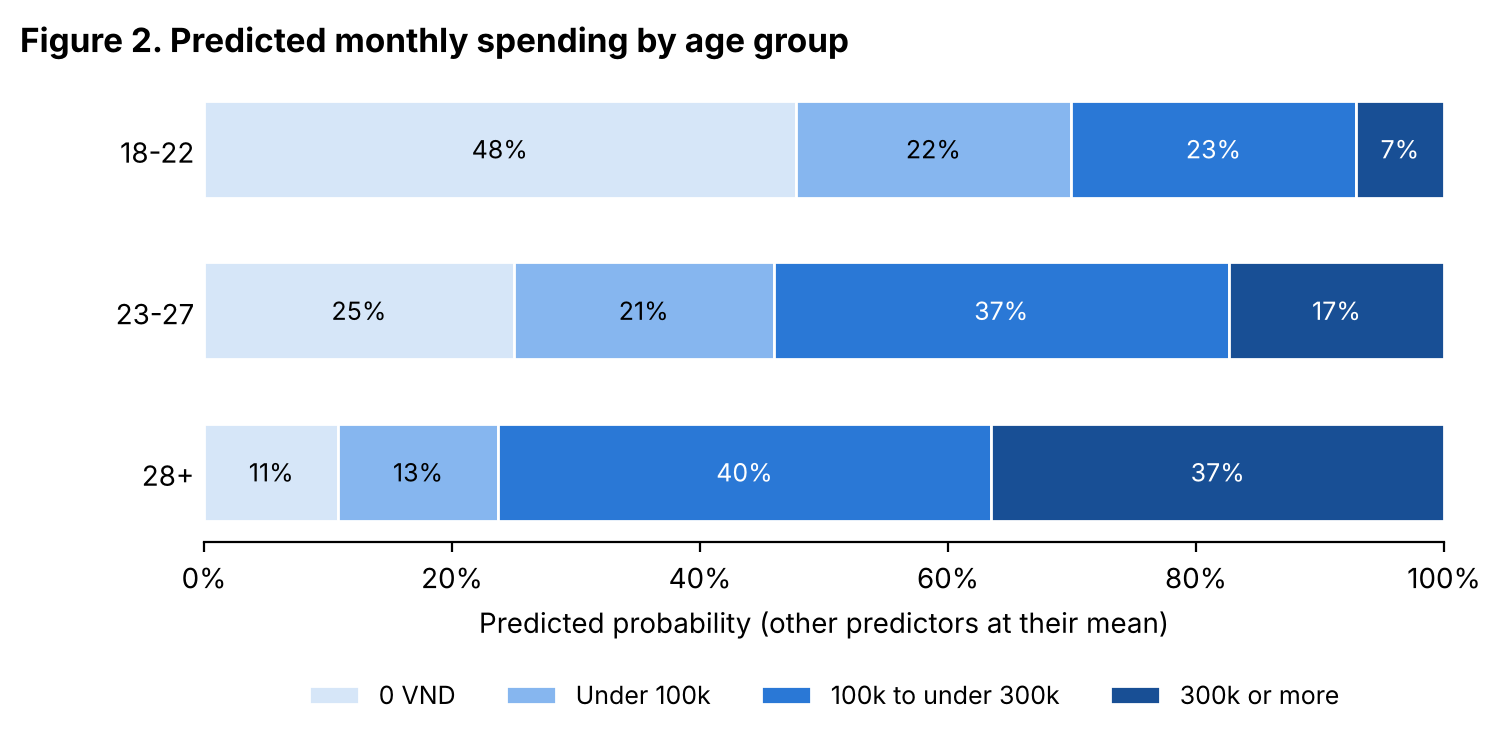

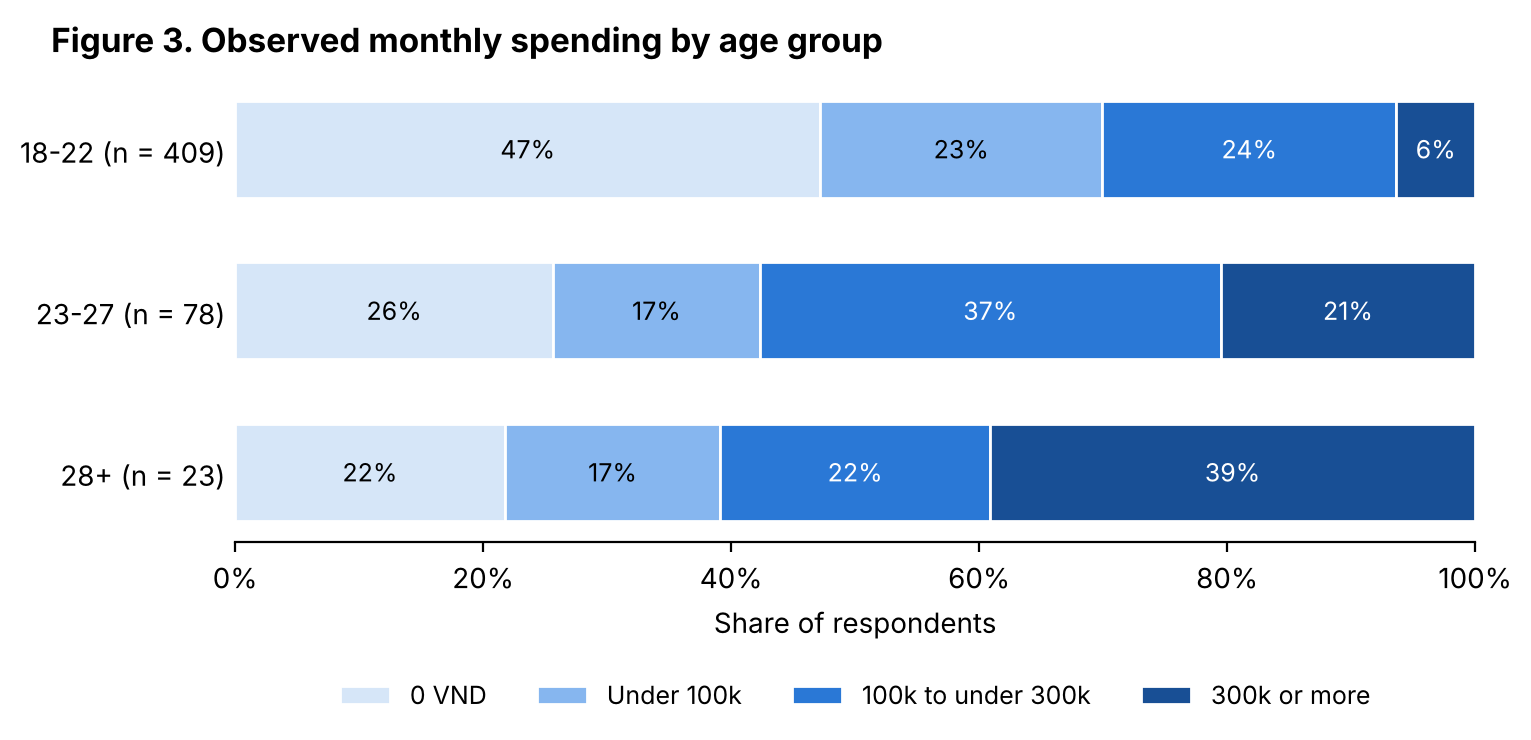

In [9]:
mau = ["#d6e6f8", "#86b6ef", "#2a78d6", "#184f95"]   # light to dark = low to high spending

def ve_chong(bang, tieu_de, file, xlabel):
    fig, ax = plt.subplots(figsize=(8, 3))
    trai = np.zeros(len(bang))
    for j, lv in enumerate(muc):
        v = bang[lv].values
        ax.barh(range(len(bang)), v, left=trai, color=mau[j], edgecolor="white", height=0.6, label=lv)
        for i, val in enumerate(v):
            if val >= 0.06:
                ax.text(trai[i] + val / 2, i, f"{val:.0%}", ha="center", va="center", fontsize=9,
                        color="white" if j >= 2 else "black")
        trai += v
    ax.set_yticks(range(len(bang))); ax.set_yticklabels(bang.index); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.legend(ncol=4, frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.25))
    fig.suptitle(tieu_de, x=0.01, ha="left", fontweight="bold")
    fig.savefig(FIG / file, dpi=200, bbox_inches="tight")
    plt.show()

ve_chong(du_doan, "Figure 2. Predicted monthly spending by age group", "predicted_spending_by_age.png",
         "Predicted probability (other predictors at their mean)")
ve_chong(quan_sat, "Figure 3. Observed monthly spending by age group", "spending_by_age_observed.png",
         "Share of respondents")

## 6. Answer to the Stage 3 question

The summary below is computed from the tables above, so it updates if the data change.

In [10]:
def dong(name):
    r = ket_qua.loc[name]
    p = "p < 0.001" if r["p"] < 0.001 else f"p = {r['p']:.3f}"
    return f"OR {r['OR']:.2f} ({r['CI_low']:.2f}–{r['CI_high']:.2f}), {p}"

ns = [nhan[n] for n in X_COLS if ket_qua.loc[n, "p"] >= 0.05]
om = brant.iloc[0]
key = pd.DataFrame([
    ["Age group (per step up)", dong("AGE_code")],
    ["Perceived price fairness (per point)", dong("PRICE")],
    ["Perceived pity fairness (per point)", dong("PITY2")],
    ["Not significant", ", ".join(ns)],
    ["McFadden R2 (main / + INT)", f"{mo_hinh.prsquared:.3f} / {tham_chieu.prsquared:.3f}"],
    ["Highest VIF", f"{vif.max():.2f} ({vif.idxmax()})"],
    ["Brant omnibus", f"chi2 = {om['chi2']:.2f}, df = {int(om['df'])}, p = {om['p']:.3f}"],
    ["Predicted 300k or more (18-22 vs 28+)", f"{du_doan.iloc[0, 3]:.1%} vs {du_doan.iloc[2, 3]:.1%}"],
    ["Predicted 0 VND (18-22 vs 28+)", f"{du_doan.iloc[0, 0]:.1%} vs {du_doan.iloc[2, 0]:.1%}"],
    ["Respondents aged 28+", str(n_tuoi[2])],
], columns=["Result", "Value"])
key.to_csv(TAB / "stage3_key_findings.csv", index=False, encoding="utf-8-sig")

print(f"- Age is the strongest factor: {dong('AGE_code')}. Predicted share spending 300k or more rises "
      f"from {du_doan.iloc[0, 3]:.0%} (18-22) to {du_doan.iloc[2, 3]:.0%} (28+).")
print(f"- Perceived price fairness goes with higher spending ({dong('PRICE')}); "
      f"perceived pity fairness with lower spending ({dong('PITY2')}).")
print(f"- No association: {', '.join(ns)}.")
print(f"- Low fit (McFadden R2 = {mo_hinh.prsquared:.3f}); assumptions hold "
      f"(max VIF {vif.max():.2f}, Brant p = {om['p']:.3f}).")

- Age is the strongest factor: OR 2.74 (1.97–3.81), p < 0.001. Predicted share spending 300k or more rises from 7% (18-22) to 37% (28+).
- Perceived price fairness goes with higher spending (OR 1.29 (1.02–1.63), p = 0.031); perceived pity fairness with lower spending (OR 0.77 (0.62–0.95), p = 0.014).
- No association: Perceived luck, Satisfaction, Tenure (per group).
- Low fit (McFadden R2 = 0.035); assumptions hold (max VIF 1.63, Brant p = 0.219).


**Notes for the report**

- Write "is associated with", not "causes": the survey is a one-time snapshot.
- Income was not measured; it is a possible explanation for the age effect, not a finding.
- The pity result appears only with price fairness held constant (they correlate at 0.53) and is driven mainly by the top spending group; report it as weak.
- Only 23 respondents are aged 28+, so the top age estimate is less precise.